<a href="https://colab.research.google.com/github/marinazakimi/ECAA08--Grupo-06/blob/main/etapa-03-arvores/%2019_Algoritmo_de_Kruskal_e_Prim.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula 19 — Algoritmos de Kruskal e Prim

**ECAA08 — Arquitetura de Sistemas SCADA | Grupo 06**  
**Integrantes:** Arthur, Caique, Luis Felipe e Marina  
**Planta:** Sistema SCADA aplicado a um Drone Agrícola de Pulverização  
**Etapa 3:** Árvores — planejamento e execução supervisionada de missões de pulverização


## 1. Contexto e objetivo no SCADA

O servidor SCADA disponibiliza ao operador uma referência de conectividade entre a base e os acessos T1–T5. Uma ligação existe somente quando o segmento entre dois pontos é admissível no mapa. A árvore geradora mínima (AGM) reduz a soma desses comprimentos e ajuda a discutir o mapa disponível para o planejamento.

Os vértices são posições geográficas locais, em metros; as arestas representam possibilidades de deslocamento aéreo. Nenhum comprimento representa tubulação. A HMI pode exibir o grafo, a AGM e os pontos isolados. A saída desta aula não autoriza aplicação nem especifica a sequência completa de visita e retorno.

## 2. Modelo e fundamentação

Para um grafo simples não dirigido $G=(V,E)$ com pesos $w$, buscamos uma árvore que conecte todos os vértices e minimize $\sum_{e\in T}w(e)$. Usamos $w(u,v)=\|p_u-p_v\|_2$. Uma árvore conectada tem $|V|-1$ arestas; uma floresta com $c$ componentes tem $|V|-c$. A contagem precisa ser acompanhada da verificação de conectividade.

Kruskal ordena arestas e utiliza conjuntos disjuntos para evitar ciclos: $O(E\log E)$ para ordenação, além do custo quase linear das uniões. Prim expande uma fronteira a partir da BASE; a implementação *lazy* utiliza heap de arestas, com $O(V+E\log E)$. Ambos aplicam escolhas gulosas justificadas pela propriedade do corte. Empates podem produzir árvores diferentes com o mesmo custo.

O mapa é o mesmo da Aula 22. A geometria utiliza raio ilustrativo de 0,6 m e folga de 1,4 m; a margem total de 2 m é uma hipótese desta etapa. Obstáculos são inflados e as bordas externas reduzidas. São verificadas interseções de segmentos completos, inclusive tangência.

## 3. Procedimento e demonstração

1. Construir todas as conexões admissíveis entre os seis pontos herdados da Aula 17.
2. Mostrar as decisões de Kruskal, incluindo rejeições por ciclo.
3. Iniciar Prim na BASE e comparar a ordem das escolhas.
4. Verificar as componentes por busca independente e comparar o custo com enumeração exata desta pequena instância.
5. Remover as ligações de T1 e demonstrar a floresta resultante.

Pergunta para a apresentação: por que uma AGM não é um circuito de missão? Porque não inclui uma ordem com retorno e pode exigir repetição de arestas para visitar todos os ramos.

## 4. Experimentos executáveis

Execute as células em ordem, com a pasta `Arquivos_de_Apoio` ao lado do notebook. Os algoritmos centrais aparecem abaixo; dados, funções comuns e verificações estão nos arquivos de apoio. Não há download de dados durante a execução.

In [ ]:
from pathlib import Path
import sys
# Funciona na pasta da etapa, na raiz do repositório ou em uma subpasta da etapa.
origem = Path.cwd().resolve()
candidatos = [p / sufixo for p in [origem, *origem.parents]
              for sufixo in (Path('.'), Path('etapa-03-arvores'))]
ETAPA = next((p for p in candidatos if (p/'Arquivos_de_Apoio'/'scada_arvores.py').is_file()), None)
if ETAPA is None:
    raise FileNotFoundError('Extraia o pacote completo e abra o notebook na pasta etapa-03-arvores.')
sys.path.insert(0, str(ETAPA/'Arquivos_de_Apoio'))
from scada_arvores import *
import scada_arvores as core
import visualizacao as vis
from verificacoes import TESTES, conferir_rrt
import matplotlib.pyplot as plt
import json
print('Sistema SCADA do Drone Agrícola | Grupo 06 | simulação acadêmica')


Sistema SCADA do Drone Agrícola | Grupo 06 | simulação acadêmica


In [ ]:
def kruskal(vertices, arestas):
    validar_grafo(vertices, arestas)
    pai = {v: v for v in vertices}; tamanho = dict.fromkeys(vertices, 1)
    def raiz(v):
        while pai[v] != v:
            pai[v] = pai[pai[v]]; v = pai[v]
        return v
    arvore, trilha = [], []
    for u, v, w in sorted(arestas, key=lambda e: (e[2], e[0], e[1])):
        a, b = raiz(u), raiz(v); aceita = a != b
        trilha.append((u, v, w, 'ACEITA' if aceita else 'CICLO'))
        if aceita:
            if tamanho[a] < tamanho[b]: a, b = b, a
            pai[b] = a; tamanho[a] += tamanho[b]; arvore.append((u, v, w))
    return arvore, trilha


In [ ]:
def prim(vertices, arestas, inicio='BASE'):
    validar_grafo(vertices, arestas)
    adj = {v: [] for v in vertices}
    for u, v, w in arestas:
        adj[u].append((w, u, v)); adj[v].append((w, v, u))
    arvore, trilha, vistos = [], [], set()
    ordem = ([inicio] if inicio in adj else []) + [v for v in vertices if v != inicio]
    for raiz in ordem:
        if raiz in vistos: continue
        vistos.add(raiz); fila = list(adj[raiz]); heapq.heapify(fila)
        while fila:
            w, u, v = heapq.heappop(fila)
            aceita = v not in vistos
            trilha.append((u, v, w, 'ACEITA' if aceita else 'VISITADO'))
            if aceita:
                vistos.add(v); arvore.append((u, v, w))
                for edge in adj[v]: heapq.heappush(fila, edge)
    return arvore, trilha


### Decisões dos dois algoritmos

In [ ]:
vertices=list(PONTOS); edges=arestas_mapa()
for nome,alg in [('Kruskal',kruskal),('Prim',prim)]:
    arv,trilha=alg(vertices,edges)
    print(nome, '| custo:',round(custo(arv),3),'m')
    for u,v,w,decisao in trilha: print(u,v,round(w,3),decisao)
    verificar_floresta(vertices,edges,arv)

Kruskal | custo: 386.853 m
BASE T3 36.056 ACEITA
T2 T5 44.721 ACEITA
T1 T2 67.082 ACEITA
T4 T5 86.023 ACEITA
T1 T5 106.301 CICLO
T2 T4 130.384 CICLO
T3 T4 152.971 ACEITA
BASE T4 180.278 CICLO
T1 T4 191.05 CICLO
Prim | custo: 386.853 m
BASE T3 36.056 ACEITA
T3 BASE 36.056 VISITADO
T3 T4 152.971 ACEITA
T4 T5 86.023 ACEITA
T5 T2 44.721 ACEITA
T2 T5 44.721 VISITADO
T2 T1 67.082 ACEITA
T1 T2 67.082 VISITADO
T5 T4 86.023 VISITADO
T1 T5 106.301 VISITADO
T5 T1 106.301 VISITADO
T2 T4 130.384 VISITADO
T4 T2 130.384 VISITADO
T4 T3 152.971 VISITADO
BASE T4 180.278 VISITADO
T4 BASE 180.278 VISITADO
T1 T4 191.05 VISITADO
T4 T1 191.05 VISITADO


### Mapa e floresta após interdição

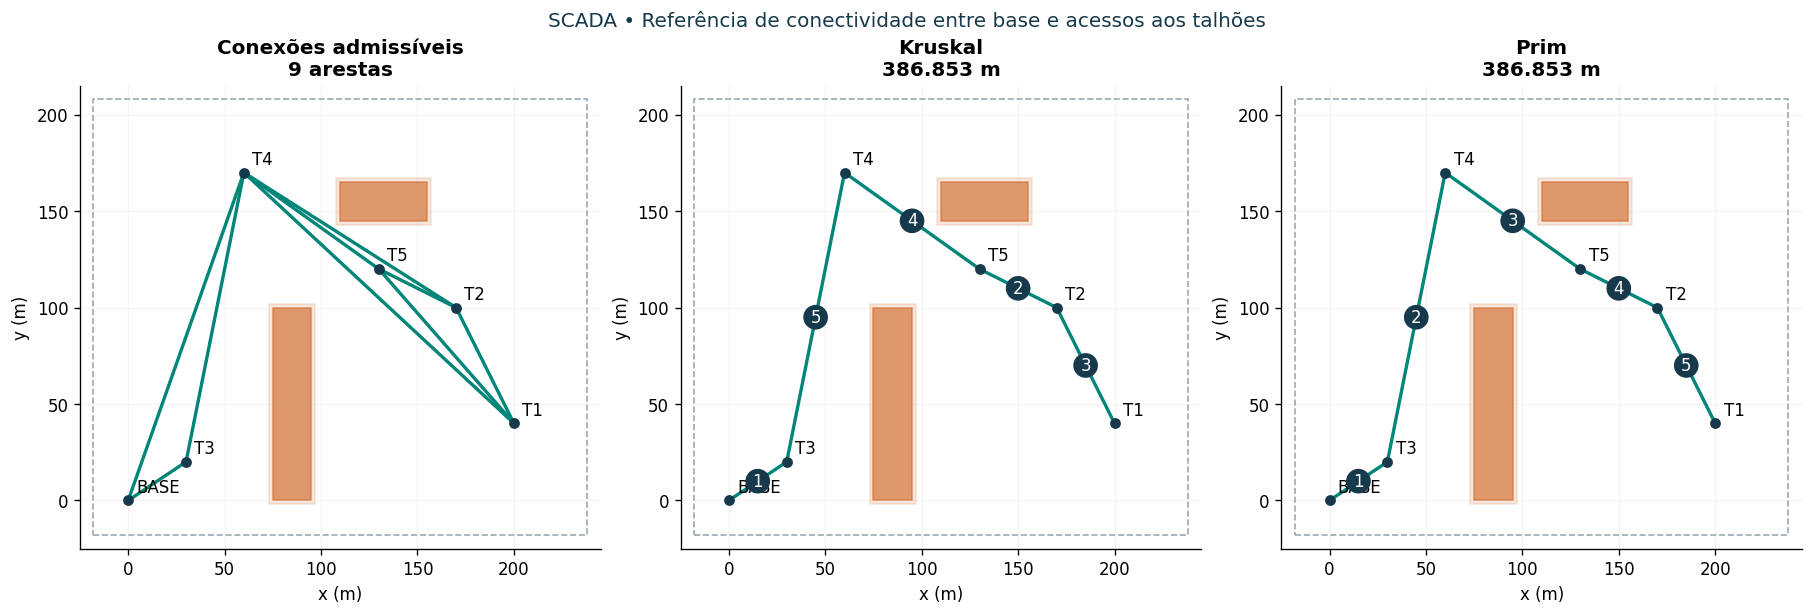

Componentes: {frozenset({'BASE', 'T5', 'T3', 'T4', 'T2'}), frozenset({'T1'})}
Arestas: 4


In [ ]:
vis.figura19(); plt.show()
interditadas=[e for e in edges if 'T1' not in e[:2]]
floresta,_=kruskal(vertices,interditadas)
print('Componentes:',componentes(vertices,floresta))
print('Arestas:',len(floresta))

### Verificação e resultados de referência

As verificações confrontam propriedades, referências independentes e casos de fronteira. Consulte `Arquivos_de_Apoio/verificacoes.py` para os critérios completos.

In [ ]:
RESUMO = TESTES[19]()
print(json.dumps(RESUMO, ensure_ascii=False, indent=2))
print('Verificações da aula 19: APROVADAS')

{
  "custo_m": 386.85274970783917,
  "vertices": 6,
  "arestas_admissiveis": 9
}
Verificações da aula 19: APROVADAS


## 5. Interpretação, limites e continuidade

A AGM é referência de conectividade e soma de ligações, não uma rota completa nem um cálculo de autonomia. Ela fornece uma cota para certos passeios no mesmo grafo com pesos não negativos, mas não pode ser comparada diretamente com um trajeto contínuo do RRT. Vento e energia não estão incluídos nos pesos. Uma desconexão deste grafo de seis pontos também não prova ausência de caminho no espaço livre: o RRT poderá criar pontos intermediários.

Na Aula 28, seu resultado aparece como informação de planejamento para a supervisão. A autorização de aplicação permanece vinculada aos permissivos e ao operador.

## 6. Referências

- [Sedgewick e Wayne — Algorithms](https://algs4.cs.princeton.edu/home/), capítulos de grafos, busca e compressão.
- [Referência curricular do professor](https://github.com/valerio-unifei/ECAA08-2026.2-Projeto/tree/main/etapa-03-arvores). Organização consultada em 16/11/2026; aplicações e figuras desta entrega são do drone.